In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "../data/raw/energy_consumption_30days.csv",
    parse_dates=["timestamp"]
)

df.head()

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


,timestamp,voltage_v,current_a,active_power_kw,power_factor,energy_kwh,is_anomaly
0,2026-01-01 00:00:00,126.793,12.908,1.560,0.953,0.390,0
1,2026-01-01 00:15:00,126.649,14.206,1.683,0.935,0.421,0
2,2026-01-01 00:30:00,128.151,14.167,1.690,0.931,0.422,0
3,2026-01-01 00:45:00,126.305,13.314,1.565,0.931,0.391,0
4,2026-01-01 01:00:00,124.130,13.604,1.529,0.906,0.382,0


In [3]:
df.shape

(2880, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2880 entries, 0 to 2879
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   timestamp        2880 non-null   datetime64[us]
 1   voltage_v        2880 non-null   float64       
 2   current_a        2880 non-null   float64       
 3   active_power_kw  2880 non-null   float64       
 4   power_factor     2880 non-null   float64       
 5   energy_kwh       2880 non-null   float64       
 6   is_anomaly       2880 non-null   int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 157.6 KB


In [5]:
df.isnull().sum()

timestamp          0
voltage_v          0
current_a          0
active_power_kw    0
power_factor       0
energy_kwh         0
is_anomaly         0
dtype: int64

In [6]:
consumo_total = df["energy_kwh"].sum()
potencia_media = df["active_power_kw"].mean()
demanda_maxima = df["active_power_kw"].max()

print(f"Consumo total: {consumo_total:.2f} kWh")
print(f"Potência média: {potencia_media:.2f} kW")
print(f"Demanda máxima: {demanda_maxima:.2f} kW")

Consumo total: 3678.26 kWh
Potência média: 5.11 kW
Demanda máxima: 26.41 kW


In [7]:
indice_pico = df["active_power_kw"].idxmax()

registro_pico = df.loc[indice_pico]

registro_pico

timestamp          2026-01-01 19:45:00
voltage_v                      126.007
current_a                      218.997
active_power_kw                  26.41
power_factor                     0.957
energy_kwh                       6.602
is_anomaly                           1
Name: 79, dtype: object

In [8]:
print("Maior demanda registrada:")
print(f"Data/hora: {registro_pico['timestamp']}")
print(f"Potência: {registro_pico['active_power_kw']:.2f} kW")
print(f"Corrente: {registro_pico['current_a']:.2f} A")
print(f"Tensão: {registro_pico['voltage_v']:.2f} V")
print(f"Fator de potência: {registro_pico['power_factor']:.3f}")

Maior demanda registrada:
Data/hora: 2026-01-01 19:45:00
Potência: 26.41 kW
Corrente: 219.00 A
Tensão: 126.01 V
Fator de potência: 0.957


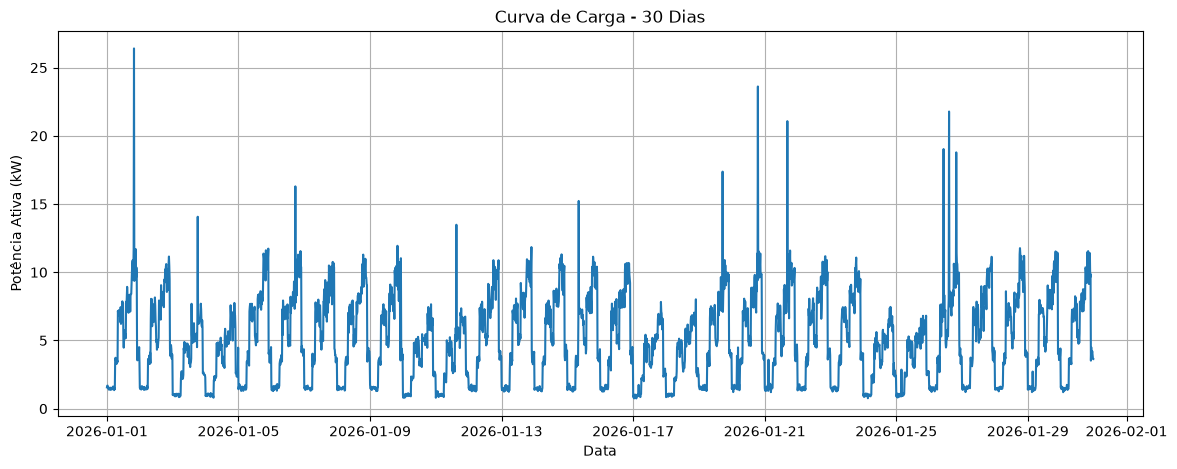

In [9]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["timestamp"],
    df["active_power_kw"]
)

plt.title("Curva de Carga - 30 Dias")
plt.xlabel("Data")
plt.ylabel("Potência Ativa (kW)")
plt.grid(True)

plt.show()

In [10]:
df["hour"] = df["timestamp"].dt.hour

perfil_horario = (
    df.groupby("hour")["active_power_kw"]
    .mean()
)

perfil_horario

hour
0     1.360742
1     1.355983
2     1.369975
3     1.409808
4     1.384025
5     1.353967
6     3.165125
7     3.176967
8     6.366317
9     6.335192
10    6.359992
11    6.413092
12    4.502617
13    4.609858
14    7.381183
15    7.223275
16    7.381525
17    7.412783
18    9.158725
19    9.441433
20    9.066958
21    9.084358
22    3.676725
23    3.617475
Name: active_power_kw, dtype: float64

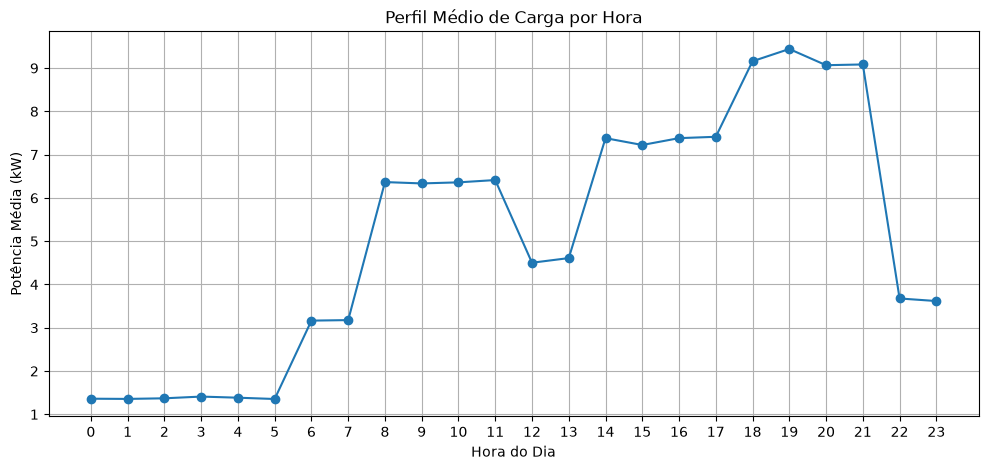

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    perfil_horario.index,
    perfil_horario.values,
    marker="o"
)

plt.title("Perfil Médio de Carga por Hora")
plt.xlabel("Hora do Dia")
plt.ylabel("Potência Média (kW)")

plt.xticks(range(0, 24))
plt.grid(True)

plt.show()

In [12]:
df["day_of_week"] = df["timestamp"].dt.dayofweek

df["day_type"] = np.where(
    df["day_of_week"] < 5,
    "Dia útil",
    "Fim de semana"
)

df[["timestamp", "day_of_week", "day_type"]].head()

,timestamp,day_of_week,day_type
0,2026-01-01 00:00:00,3,Dia útil
1,2026-01-01 00:15:00,3,Dia útil
2,2026-01-01 00:30:00,3,Dia útil
3,2026-01-01 00:45:00,3,Dia útil
4,2026-01-01 01:00:00,3,Dia útil


In [13]:
perfil_tipo_dia = (
    df.groupby(["day_type", "hour"])["active_power_kw"]
    .mean()
    .unstack(level=0)
)

perfil_tipo_dia

day_type,Dia útil,Fim de semana
hour,,
0,1.508989,0.953063
1,1.493102,0.978906
2,1.508852,0.988062
3,1.538580,1.055687
4,1.520761,1.008000
5,1.490057,0.979719
6,3.493955,2.260844
7,3.494659,2.303313
8,7.035057,4.527281


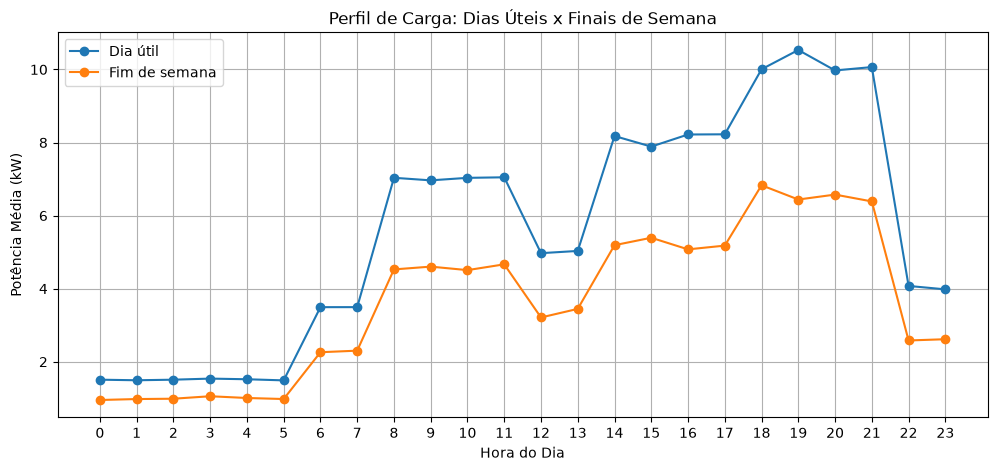

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    perfil_tipo_dia.index,
    perfil_tipo_dia["Dia útil"],
    marker="o",
    label="Dia útil"
)

plt.plot(
    perfil_tipo_dia.index,
    perfil_tipo_dia["Fim de semana"],
    marker="o",
    label="Fim de semana"
)

plt.title("Perfil de Carga: Dias Úteis x Finais de Semana")
plt.xlabel("Hora do Dia")
plt.ylabel("Potência Média (kW)")

plt.xticks(range(0, 24))
plt.grid(True)
plt.legend()

plt.show()

In [15]:
def classificar_periodo(hora):
    if 0 <= hora < 6:
        return "Madrugada"
    elif 6 <= hora < 12:
        return "Manhã"
    elif 12 <= hora < 18:
        return "Tarde"
    else:
        return "Noite"

df["periodo"] = df["hour"].apply(classificar_periodo)

df[["timestamp", "hour", "periodo"]].head()

,timestamp,hour,periodo
0,2026-01-01 00:00:00,0,Madrugada
1,2026-01-01 00:15:00,0,Madrugada
2,2026-01-01 00:30:00,0,Madrugada
3,2026-01-01 00:45:00,0,Madrugada
4,2026-01-01 01:00:00,1,Madrugada


In [16]:
consumo_por_periodo = (
    df.groupby("periodo")["energy_kwh"]
    .sum()
    .sort_values(ascending=False)
)

consumo_por_periodo

periodo
Noite        1321.380
Tarde        1155.336
Manhã         954.502
Madrugada     247.037
Name: energy_kwh, dtype: float64

In [17]:
percentual_por_periodo = (
    consumo_por_periodo /
    consumo_por_periodo.sum()
) * 100

percentual_por_periodo

periodo
Noite        35.924100
Tarde        31.409894
Manhã        25.949859
Madrugada     6.716147
Name: energy_kwh, dtype: float64

In [18]:
resumo_periodos = pd.DataFrame({
    "Consumo (kWh)": consumo_por_periodo,
    "Percentual (%)": percentual_por_periodo
})

resumo_periodos = resumo_periodos.round(2)

resumo_periodos

,Consumo (kWh),Percentual (%)
periodo,,
Noite,1321.38,35.92
Tarde,1155.34,31.41
Manhã,954.50,25.95
Madrugada,247.04,6.72


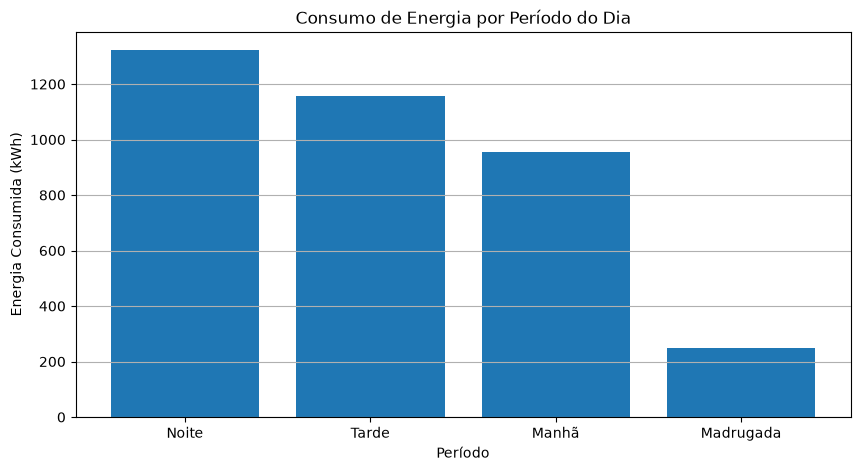

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(
    resumo_periodos.index,
    resumo_periodos["Consumo (kWh)"]
)

plt.title("Consumo de Energia por Período do Dia")
plt.xlabel("Período")
plt.ylabel("Energia Consumida (kWh)")
plt.grid(axis="y")

plt.show()

In [20]:
consumo_por_hora = (
    df.groupby("hour")["energy_kwh"]
    .sum()
)

hora_maior_consumo = consumo_por_hora.idxmax()
maior_consumo = consumo_por_hora.max()

print(f"Hora de maior consumo: {hora_maior_consumo}:00")
print(f"Consumo acumulado nessa hora: {maior_consumo:.2f} kWh")

Hora de maior consumo: 19:00
Consumo acumulado nessa hora: 283.25 kWh


In [21]:
consumo_pico = df.loc[
    df["hour"].between(18, 21),
    "energy_kwh"
].sum()

consumo_total = df["energy_kwh"].sum()

percentual_pico = (
    consumo_pico /
    consumo_total
) * 100

print(f"Consumo total: {consumo_total:.2f} kWh")
print(f"Consumo entre 18h e 21h: {consumo_pico:.2f} kWh")
print(f"Percentual no horário de pico: {percentual_pico:.2f}%")

Consumo total: 3678.26 kWh
Consumo entre 18h e 21h: 1102.54 kWh
Percentual no horário de pico: 29.97%


In [22]:
print(
    f"{percentual_pico:.1f}% de toda a energia consumida "
    f"ocorre entre 18h e 21h."
)

30.0% de toda a energia consumida ocorre entre 18h e 21h.


In [23]:
from sklearn.ensemble import IsolationForest

In [24]:
features = [
    "voltage_v",
    "current_a",
    "active_power_kw",
    "power_factor",
    "energy_kwh"
]

X = df[features]

X.head()

,voltage_v,current_a,active_power_kw,power_factor,energy_kwh
0,126.793,12.908,1.560,0.953,0.390
1,126.649,14.206,1.683,0.935,0.421
2,128.151,14.167,1.690,0.931,0.422
3,126.305,13.314,1.565,0.931,0.391
4,124.130,13.604,1.529,0.906,0.382


In [26]:
modelo_anomalia = IsolationForest(
    contamination=20 / len(df),
    random_state=42
)

df["anomaly_prediction"] = modelo_anomalia.fit_predict(X)

In [27]:
df["predicted_anomaly"] = np.where(
    df["anomaly_prediction"] == -1,
    1,
    0
)

print(
    "Anomalias detectadas:",
    df["predicted_anomaly"].sum()
)

Anomalias detectadas: 20


In [28]:
comparacao = pd.crosstab(
    df["is_anomaly"],
    df["predicted_anomaly"],
    rownames=["Anomalia Real"],
    colnames=["Anomalia Detectada"]
)

comparacao

Anomalia Detectada,0,1
Anomalia Real,,
0,2851,9
1,9,11


In [29]:
df["potencia_mediana_hora"] = (
    df.groupby("hour")["active_power_kw"]
    .transform("median")
)

df["desvio_potencia"] = (
    df["active_power_kw"] -
    df["potencia_mediana_hora"]
)

df["razao_potencia"] = (
    df["active_power_kw"] /
    df["potencia_mediana_hora"]
)

In [30]:
df[
    [
        "timestamp",
        "active_power_kw",
        "potencia_mediana_hora",
        "desvio_potencia",
        "razao_potencia"
    ]
].head()

,timestamp,active_power_kw,potencia_mediana_hora,desvio_potencia,razao_potencia
0,2026-01-01 00:00:00,1.560,1.444,0.116,1.080332
1,2026-01-01 00:15:00,1.683,1.444,0.239,1.165512
2,2026-01-01 00:30:00,1.690,1.444,0.246,1.170360
3,2026-01-01 00:45:00,1.565,1.444,0.121,1.083795
4,2026-01-01 01:00:00,1.529,1.438,0.091,1.063282


In [31]:
features_v2 = [
    "voltage_v",
    "power_factor",
    "active_power_kw",
    "desvio_potencia",
    "razao_potencia"
]

X_v2 = df[features_v2]

In [32]:
modelo_anomalia_v2 = IsolationForest(
    contamination=20 / len(df),
    random_state=42
)

df["prediction_v2"] = modelo_anomalia_v2.fit_predict(X_v2)

df["predicted_anomaly_v2"] = np.where(
    df["prediction_v2"] == -1,
    1,
    0
)

In [33]:
comparacao_v2 = pd.crosstab(
    df["is_anomaly"],
    df["predicted_anomaly_v2"],
    rownames=["Anomalia Real"],
    colnames=["Anomalia Detectada"]
)

comparacao_v2

Anomalia Detectada,0,1
Anomalia Real,,
0,2856,4
1,4,16


In [34]:
from sklearn.metrics import classification_report

print(
    classification_report(
        df["is_anomaly"],
        df["predicted_anomaly_v2"]
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2860
           1       0.80      0.80      0.80        20

    accuracy                           1.00      2880
   macro avg       0.90      0.90      0.90      2880
weighted avg       1.00      1.00      1.00      2880



In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(
    df["is_anomaly"],
    df["predicted_anomaly_v2"]
)

recall = recall_score(
    df["is_anomaly"],
    df["predicted_anomaly_v2"]
)

f1 = f1_score(
    df["is_anomaly"],
    df["predicted_anomaly_v2"]
)

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

Precision: 80.00%
Recall: 80.00%
F1-score: 80.00%


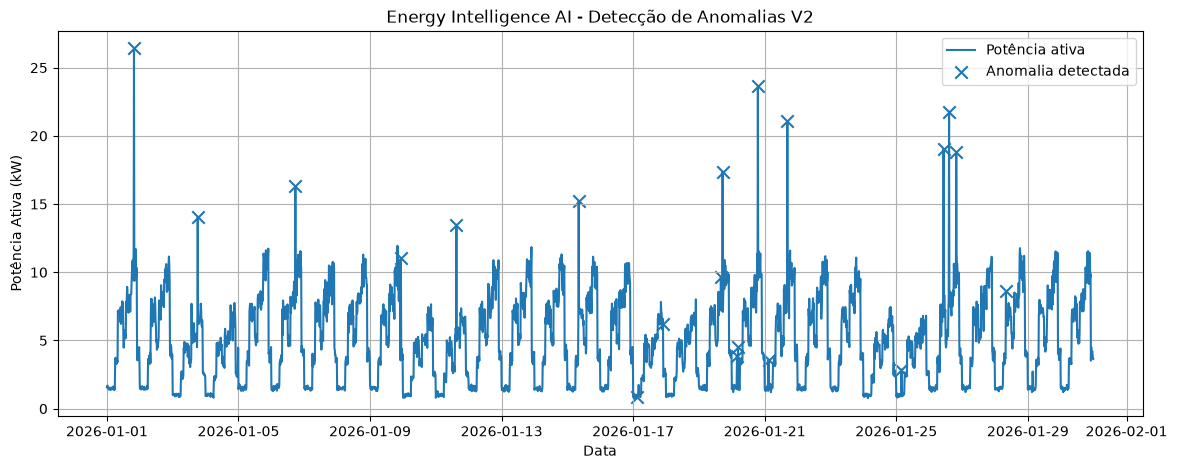

In [36]:
anomalias_v2 = df[
    df["predicted_anomaly_v2"] == 1
]

plt.figure(figsize=(14, 5))

plt.plot(
    df["timestamp"],
    df["active_power_kw"],
    label="Potência ativa"
)

plt.scatter(
    anomalias_v2["timestamp"],
    anomalias_v2["active_power_kw"],
    marker="x",
    s=80,
    label="Anomalia detectada"
)

plt.title("Energy Intelligence AI - Detecção de Anomalias V2")
plt.xlabel("Data")
plt.ylabel("Potência Ativa (kW)")
plt.legend()
plt.grid(True)

plt.show()

In [37]:
df[
    df["predicted_anomaly_v2"] == 1
][
    [
        "timestamp",
        "active_power_kw",
        "potencia_mediana_hora",
        "razao_potencia",
        "is_anomaly"
    ]
].sort_values(
    "razao_potencia",
    ascending=False
)

,timestamp,active_power_kw,potencia_mediana_hora,razao_potencia,is_anomaly
1842,2026-01-20 04:30:00,4.489,1.4230,3.154603,1
2442,2026-01-26 10:30:00,19.034,6.6625,2.856886,1
858,2026-01-09 22:30:00,11.029,3.8750,2.846194,1
2458,2026-01-26 14:30:00,21.784,7.7525,2.809932,1
1986,2026-01-21 16:30:00,21.080,7.7650,2.714746,1
79,2026-01-01 19:45:00,26.410,9.8010,2.694623,1
1839,2026-01-20 03:45:00,3.867,1.4465,2.673349,1
1931,2026-01-21 02:45:00,3.588,1.4290,2.510847,1
1900,2026-01-20 19:00:00,23.621,9.8010,2.410060,1
1377,2026-01-15 08:15:00,15.228,6.6875,2.277084,1
